In [14]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re
import string


## datastet loading

In [15]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# Config (same idea as proj.ipynb)
SEED = 42
FAST_MODE = True   # True = smaller subsets for faster experiments
MAX_TRAIN = 10_000 if FAST_MODE else None
MAX_TEST  = 5_000  if FAST_MODE else None

# SST-2: the official test split has no labels (-1), so we split the labelled train split 80/20 (stratified).
sst2_all = load_dataset("stanfordnlp/sst2")["train"].to_pandas().rename(columns={"sentence": "text"})[["text", "label"]]
sst2_train, sst2_test = train_test_split(sst2_all, test_size=0.2, stratify=sst2_all["label"], random_state=SEED)

# IMDB: use the official 25k train / 25k test split.
imdb = load_dataset("stanfordnlp/imdb")
imdb_train = imdb["train"].to_pandas()[["text", "label"]]
imdb_test  = imdb["test"].to_pandas()[["text", "label"]]

def subsample(df, n):
    if n is None or len(df) <= n:
        return df.reset_index(drop=True)
    small, _ = train_test_split(df, train_size=n, stratify=df["label"], random_state=SEED)  # keeps class balance
    return small.reset_index(drop=True)

data = {
    "SST2": (subsample(sst2_train, MAX_TRAIN), subsample(sst2_test, MAX_TEST)),
    "IMDB": (subsample(imdb_train, MAX_TRAIN), subsample(imdb_test, MAX_TEST)),
}
for name, (tr, te) in data.items():
    print(f"{name}: train {len(tr):,} (pos {tr.label.mean():.1%}) | test {len(te):,} (pos {te.label.mean():.1%})")

SST2: train 10,000 (pos 55.8%) | test 5,000 (pos 55.8%)
IMDB: train 10,000 (pos 50.0%) | test 5,000 (pos 50.0%)


## Exploratory Data Analysis (EDA)

Class balance, text length, and most frequent words for SST-2 and IMDB (using the loaded `data` splits).


===== SST2 =====
Shape: (15000, 7)
Missing values:
 text     0
label    0
dtype: int64
Duplicate texts: 20
Label counts:
 sentiment
Positive    8367
Negative    6633
Name: count, dtype: int64
Length stats:
         n_chars   n_words
count  15000.00  15000.00
mean      54.23      9.51
std       44.08      8.18
min        3.00      1.00
25%       21.00      3.00
50%       39.00      7.00
75%       76.00     14.00
max      268.00     51.00

===== IMDB =====
Shape: (15000, 7)
Missing values:
 text     0
label    0
dtype: int64
Duplicate texts: 37
Label counts:
 sentiment
Positive    7500
Negative    7500
Name: count, dtype: int64
Length stats:
         n_chars   n_words
count  15000.00  15000.00
mean    1311.65    231.45
std      987.25    170.64
min       41.00      4.00
25%      701.00    127.00
50%      972.00    173.00
75%     1597.25    282.00
max    13704.00   2470.00


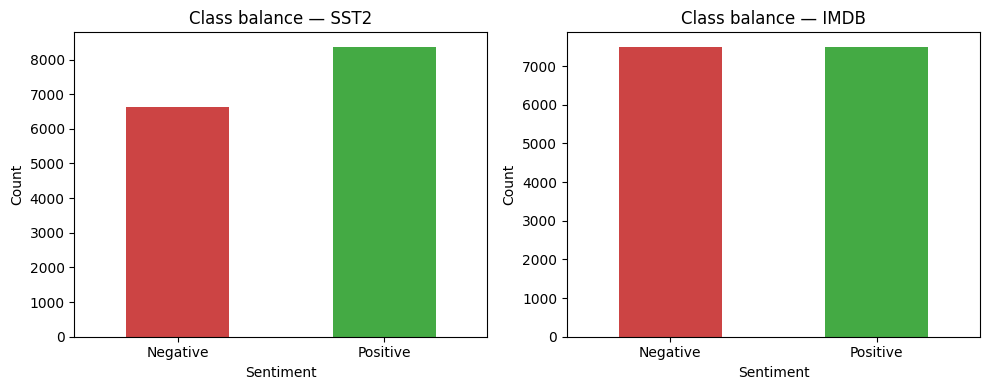

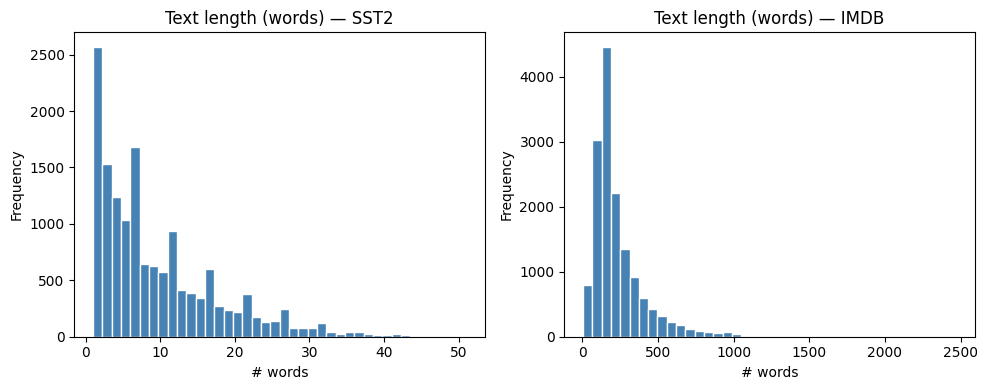

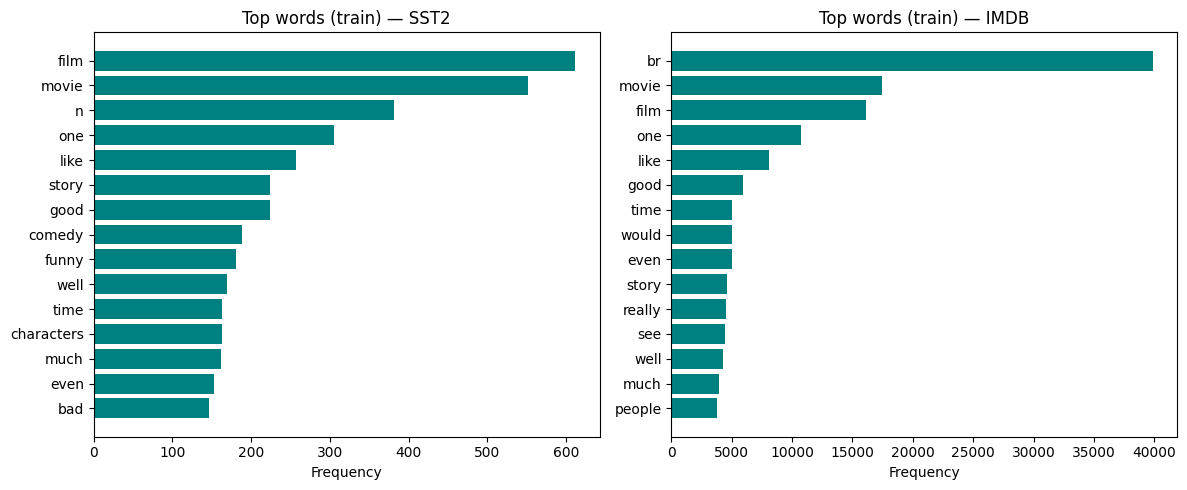

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
from nltk.corpus import stopwords
import nltk
nltk.download("stopwords", quiet=True)

label_names = {0: "Negative", 1: "Positive"}
stop_eda = set(stopwords.words("english"))

def prepare_eda_df(train_df, test_df, name):
    df = pd.concat([
        train_df.assign(split="train"),
        test_df.assign(split="test"),
    ], ignore_index=True).copy()
    df["sentiment"] = df["label"].map(label_names)
    df["n_chars"] = df["text"].astype(str).str.len()
    df["n_words"] = df["text"].astype(str).str.split().str.len()
    df["dataset"] = name
    return df

eda = {
    name: prepare_eda_df(tr, te, name)
    for name, (tr, te) in data.items()
}

for name, df in eda.items():
    print(f"\n===== {name} =====")
    print("Shape:", df.shape)
    print("Missing values:\n", df[["text", "label"]].isnull().sum())
    print("Duplicate texts:", df["text"].duplicated().sum())
    print("Label counts:\n", df["sentiment"].value_counts())
    print("Length stats:\n", df[["n_chars", "n_words"]].describe().round(2))

# Class balance
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, df) in zip(axes, eda.items()):
    df["sentiment"].value_counts().reindex(["Negative", "Positive"]).plot(
        kind="bar", ax=ax, color=["#c44", "#4a4"]
    )
    ax.set_title(f"Class balance — {name}")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

# Text length histograms
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, df) in zip(axes, eda.items()):
    ax.hist(df["n_words"], bins=40, color="steelblue", edgecolor="white")
    ax.set_title(f"Text length (words) — {name}")
    ax.set_xlabel("# words")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

# Most frequent words (train split only)
def top_words(texts, n=15):
    words = []
    for t in texts:
        toks = re.findall(r"[a-z]+", str(t).lower())
        words.extend(w for w in toks if w not in stop_eda)
    return Counter(words).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, (tr, te)) in zip(axes, data.items()):
    tops = top_words(tr["text"], n=15)
    labels, counts = zip(*tops)
    ax.barh(list(labels)[::-1], list(counts)[::-1], color="teal")
    ax.set_title(f"Top words (train) — {name}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

## preprocessing


### lowercasing

In [17]:
def lower_case(text):
    return text.lower()
lowered = {}

for name , (train, test) in data.items(): 
    train_lc = train.copy()
    train_lc['text'] = train_lc['text'].apply(lower_case)
    test_lc = test.copy()
    test_lc['text'] = test_lc['text'].apply(lower_case)
    lowered[name] = (train_lc, test_lc)

print("BEFORE:", data["IMDB"][0]["text"].iloc[0][:120])
print("AFTER :", lowered["IMDB"][0]["text"].iloc[0][:120])

BEFORE: It's amazing that actress P.J. Soles didn't become a big star after playing Riff Randall, #1 fan of the punk rock group 
AFTER : it's amazing that actress p.j. soles didn't become a big star after playing riff randall, #1 fan of the punk rock group 


### tokenisation 

In [18]:
from nltk.tokenize import word_tokenize

nltk.download("punkt", quiet = True)
nltk.download("punkt_tab", quiet = True)

def tokenize(text): 
    return word_tokenize(text)

tokenized = {}

for name , (train, test) in lowered.items():
    train_tk = train.copy()
    test_tk = test.copy()

    train_tk['text'] = train_tk['text'].apply(tokenize)
    test_tk['text'] = test_tk['text'].apply(tokenize)

    tokenized[name] = (train_tk, test_tk)

print("BEFORE (string):", lowered["IMDB"][0]["text"].iloc[0][:120])
print("AFTER  (tokens):", tokenized["IMDB"][0]["text"].iloc[0][:20])
print("Number of tokens:", len(tokenized["IMDB"][0]["text"].iloc[0]))


BEFORE (string): it's amazing that actress p.j. soles didn't become a big star after playing riff randall, #1 fan of the punk rock group 
AFTER  (tokens): ['it', "'s", 'amazing', 'that', 'actress', 'p.j', '.', 'soles', 'did', "n't", 'become', 'a', 'big', 'star', 'after', 'playing', 'riff', 'randall', ',', '#']
Number of tokens: 262


### stop words 

In [19]:
from nltk.corpus import stopwords
nltk.download("stopwords", quiet = True)

STOP = set(stopwords.words("english"))
# Small_Negation_Words=[‘no’,’not’,’nor’,’none’,’nothing’,’isnt’,’cannot’,’werent’,’rather’,‘might’,’neither’,’dont’,’could’,’doesnt’,’couldnt’,’couldve’,’wasnt’,’didnt’,’would’,’wouldnt’,‘wouldve’,’should’,’shouldnt’,’shouldve’,’neverending’,’nobody’,’scare’,’scares’,’less’,’hardly’]. 

# (PDF) Various Pre-processing Strategies for Domain-Based Sentiment Analysis of Unbalanced Large-Scale Reviews. Available from: https://www.researchgate.net/publication/344451966_Various_Pre-processing_Strategies_for_Domain-Based_Sentiment_Analysis_of_Unbalanced_Large-Scale_Reviews [accessed Oct 18 2026].

NEGATIONS = {
    "no", "not", "nor", "none", "nothing", "isnt", "cannot", "werent",
    "rather", "might", "neither", "dont", "could", "doesnt", "couldnt",
    "couldve", "wasnt", "didnt", "would", "wouldnt", "wouldve",
    "should", "shouldnt", "shouldve", "neverending", "nobody",
    "scare", "scares", "less", "hardly",
}

STOP = STOP - NEGATIONS 

def remove_stopwords(tokens):
    return [word for word in tokens if word not in STOP]

no_stop = {}

for name , (train, test) in tokenized.items():
    train_ns = train.copy()
    test_ns = test.copy()

    train_ns['text'] = train_ns['text'].apply(remove_stopwords)
    test_ns['text'] = test_ns['text'].apply(remove_stopwords)

    no_stop[name] = (train_ns, test_ns)


print("BEFORE:", tokenized["IMDB"][0]["text"].iloc[0][:20])
print("AFTER :", no_stop["IMDB"][0]["text"].iloc[0][:20])



BEFORE: ['it', "'s", 'amazing', 'that', 'actress', 'p.j', '.', 'soles', 'did', "n't", 'become', 'a', 'big', 'star', 'after', 'playing', 'riff', 'randall', ',', '#']
AFTER : ["'s", 'amazing', 'actress', 'p.j', '.', 'soles', "n't", 'become', 'big', 'star', 'playing', 'riff', 'randall', ',', '#', '1', 'fan', 'punk', 'rock', 'group']


### stemming 

In [20]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def stem_tokens(tokens):
    return [stemmer.stem(token) for token in tokens]

stemmed = {}

for name , (train, test) in no_stop.items():
    train_stem = train.copy()
    test_stem = test.copy()

    train_stem['text'] = train_stem['text'].apply(stem_tokens)
    test_stem['text'] = test_stem['text'].apply(stem_tokens)

    stemmed[name] = (train_stem, test_stem)

print("BEFORE:", tokenized["IMDB"][0]["text"].iloc[0][:20])
print("AFTER :", stemmed["IMDB"][0]["text"].iloc[0][:20])


BEFORE: ['it', "'s", 'amazing', 'that', 'actress', 'p.j', '.', 'soles', 'did', "n't", 'become', 'a', 'big', 'star', 'after', 'playing', 'riff', 'randall', ',', '#']
AFTER : ["'s", 'amaz', 'actress', 'p.j', '.', 'sole', "n't", 'becom', 'big', 'star', 'play', 'riff', 'randal', ',', '#', '1', 'fan', 'punk', 'rock', 'group']


# feature extraction 

## Count-based representations

### TFIDF ( PAPER method )

#### TF

In [21]:
import math
from collections import Counter

def join_tokens(tokens):
    return tokens if isinstance(tokens, str) else " ".join(tokens)

# Use stemmed tokens (lists), not raw data strings
corpus = {}
for name, (train, test) in stemmed.items():
    train_text = train["text"].map(join_tokens).tolist()
    test_text  = test["text"].map(join_tokens).tolist()
    y_train = train["label"].values
    y_test  = test["label"].values
    corpus[name] = (train_text, test_text, y_train, y_test)

def cal_tf(tokens):
    # TF(t,d) = count(t,d) / length(d)
    N_d = len(tokens)
    if N_d == 0:
        return {}
    counts = Counter(tokens)
    return {t: n / N_d for t, n in counts.items()}

def cal_idf(train_text):
    # IDF(t) = log(S / S(t))  — fit on train only
    S = len(train_text)
    df = Counter()
    for doc in train_text:
        for t in set(doc.split()):
            df[t] += 1
    return {t: math.log(S / df[t]) for t in df}

def cal_tfidf(docs, idf):
    # TF-IDF(t,d) = TF(t,d) * IDF(t)
    # IMPORTANT: split into words — never iterate a string (that yields characters like 'h')
    rows = []
    for doc in docs:
        tokens = doc.split()
        tf = cal_tf(tokens)
        row = {t: tf_val * idf[t] for t, tf_val in tf.items() if t in idf}
        rows.append(row)
    return rows


In [22]:
train_text, test_text, y_train, y_test = corpus["SST2"]

idf = cal_idf(train_text)
X_train_tfidf = cal_tfidf(train_text, idf)
X_test_tfidf  = cal_tfidf(test_text, idf)

print("Vocabulary size:", len(idf))
print("Train docs:", len(X_train_tfidf), "| Test docs:", len(X_test_tfidf))
print("First doc (8 terms):", list(X_train_tfidf[0].items())[:8])

Vocabulary size: 7840
Train docs: 10000 | Test docs: 5000
First doc (8 terms): [('potenti', 0.8047189562170501), ('success', 0.7068740388108461), ('inher', 1.013966010413509), ('mixtur', 0.9501128074427603), ('bullock', 0.8913623537870433), ('bubbl', 0.9501128074427603), ('hugh', 0.9080537778651087), ('goo', 0.9780057513570365)]


### TF-IDF with bigrams

In [23]:
# TF-IDF + bigrams (same paper formulas, but features = unigrams + bigrams)
# Example: tokens ["not", "good"] → features: "not", "good", "not_good"

def make_ngrams(tokens, ngram_range=(1, 2)):
    """Build unigrams and/or bigrams from a token list."""
    features = []
    lo, hi = ngram_range
    if lo <= 1 <= hi:
        features.extend(tokens)  # unigrams
    if lo <= 2 <= hi:
        # bigrams: pair consecutive words with "_"
        features.extend([f"{tokens[i]}_{tokens[i+1]}" for i in range(len(tokens) - 1)])
    return features

def cal_idf_ngrams(train_text, ngram_range=(1, 2)):
    S = len(train_text)
    df = Counter()
    for doc in train_text:
        feats = make_ngrams(doc.split(), ngram_range)
        for t in set(feats):
            df[t] += 1
    return {t: math.log(S / df[t]) for t in df}

def cal_tfidf_ngrams(docs, idf, ngram_range=(1, 2)):
    rows = []
    for doc in docs:
        feats = make_ngrams(doc.split(), ngram_range)
        tf = cal_tf(feats)  # reuse paper TF: count / length
        row = {t: tf_val * idf[t] for t, tf_val in tf.items() if t in idf}
        rows.append(row)
    return rows

# Fit on SST-2 train, transform train + test
train_text, test_text, y_train, y_test = corpus["SST2"]

idf_bi = cal_idf_ngrams(train_text, ngram_range=(1, 2))
X_train_tfidf_bi = cal_tfidf_ngrams(train_text, idf_bi, ngram_range=(1, 2))
X_test_tfidf_bi  = cal_tfidf_ngrams(test_text,  idf_bi, ngram_range=(1, 2))

# Show that "not_good"-style features exist
example = make_ngrams(["not", "good", "movie"], ngram_range=(1, 2))
print("Example features for ['not','good','movie']:", example)
print("Vocabulary size (uni+bi):", len(idf_bi), "| unigrams only:", len(idf))
print("Train docs:", len(X_train_tfidf_bi), "| Test docs:", len(X_test_tfidf_bi))
print("First doc sample:", list(X_train_tfidf_bi[0].items())[:8])

Example features for ['not','good','movie']: ['not', 'good', 'movie', 'not_good', 'good_movie']
Vocabulary size (uni+bi): 37627 | unigrams only: 7840
Train docs: 10000 | Test docs: 5000
First doc sample: [('potenti', 0.4291834433157601), ('success', 0.3769994873657846), ('inher', 0.5407818722205382), ('mixtur', 0.5067268306361388), ('bullock', 0.47539325535308974), ('bubbl', 0.5067268306361388), ('hugh', 0.4842953481947246), ('goo', 0.5216030673904195)]


### Bag of Words 

In [24]:
from collections import Counter
def build_vocab(train_docs):
    """Vocabulary = all words seen in training (sorted for stable column order)."""
    vocab = set()
    for doc in train_docs:
        vocab.update(doc.split())
    return sorted(vocab)
def bow_binary(docs, vocab):
    """
    Each doc → vector of length |vocab|
    1 if word appears at least once, else 0.
    """
    index = {w: i for i, w in enumerate(vocab)}
    X = []
    for doc in docs:
        vec = [0] * len(vocab)
        for w in set(doc.split()):          # unique words in this doc
            if w in index:
                vec[index[w]] = 1
        X.append(vec)
    return X
# Same SST-2 splits as TF-IDF
train_text, test_text, y_train, y_test = corpus["SST2"]
vocab = build_vocab(train_text)
X_train_bow = bow_binary(train_text, vocab)
X_test_bow  = bow_binary(test_text, vocab)
print("Vocabulary size:", len(vocab))
print("First 10 words:", vocab[:10])
print("Train shape:", len(X_train_bow), "x", len(vocab))
# Tiny example from the paper
toy_vocab = ["good", "bad", "movie", "not"]
toy_doc = "not a good movie"
print("Toy:", toy_doc, "→", bow_binary([toy_doc], toy_vocab)[0])

Vocabulary size: 7840
First 10 words: ['!', '#', '$', '&', "'", "''", "'d", "'ll", "'m", "'n"]
Train shape: 10000 x 7840
Toy: not a good movie → [1, 0, 1, 1]


### Character n-grams

In [25]:
### Character n-grams (3–5)
from collections import Counter

def char_ngrams(text, n_min=3, n_max=5):
    """
    Cut text into overlapping character pieces.
    \"great\" → gre, rea, eat, grea, reat, great, ...
    """
    text = str(text).lower()
    feats = []
    for n in range(n_min, n_max + 1):
        for i in range(len(text) - n + 1):
            feats.append(text[i:i + n])
    return feats

# Toy example from the paper
print("great →", char_ngrams("great", 3, 5))

# Use lowercased text (not stemmed tokens)
# lowered[name] = (train_df, test_df) from your preprocessing
train_df, test_df = lowered["SST2"]
train_raw = train_df["text"].astype(str).tolist()
test_raw  = test_df["text"].astype(str).tolist()
y_train, y_test = train_df["label"].values, test_df["label"].values

def build_char_vocab(train_docs, n_min=3, n_max=5):
    vocab = set()
    for doc in train_docs:
        vocab.update(char_ngrams(doc, n_min, n_max))
    return sorted(vocab)

def char_bow_binary(docs, vocab, n_min=3, n_max=5):
    """Binary vector: 1 if that character n-gram appears in the doc."""
    index = {g: i for i, g in enumerate(vocab)}
    X = []
    for doc in docs:
        vec = [0] * len(vocab)
        for g in set(char_ngrams(doc, n_min, n_max)):
            if g in index:
                vec[index[g]] = 1
        X.append(vec)
    return X

vocab_char = build_char_vocab(train_raw, 3, 5)
X_train_char = char_bow_binary(train_raw, vocab_char, 3, 5)
X_test_char  = char_bow_binary(test_raw,  vocab_char, 3, 5)

print("Char vocab size:", len(vocab_char))
print("Train shape:", len(X_train_char), "x", len(vocab_char))
print("Shared pieces? greatness:",
      set(char_ngrams("greatness")) & set(char_ngrams("great")))
print("Typo grreat shares:",
      set(char_ngrams("grreat")) & set(char_ngrams("great")))

great → ['gre', 'rea', 'eat', 'grea', 'reat', 'great']
Char vocab size: 96384
Train shape: 10000 x 96384
Shared pieces? greatness: {'great', 'rea', 'grea', 'gre', 'reat', 'eat'}
Typo grreat shares: {'reat', 'rea', 'eat'}


# Classifiers 

## KNN

In [26]:
### Shared features + KNN (train SST-2 → test SST-2 & IMDB)
from sklearn.feature_extraction import DictVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

def scores(y_true, y_pred):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall":    recall_score(y_true, y_pred),
        "F1":        f1_score(y_true, y_pred),
    }

# ---- Build feature matrices ONCE (reuse in NB / LR / RF / Table 1 / CM) ----
train_sst, test_sst, y_train_sst, y_test_sst = corpus["SST2"]
_, test_imdb, _, y_test_imdb = corpus["IMDB"]

train_sst_raw = lowered["SST2"][0]["text"].astype(str).tolist()
test_sst_raw  = lowered["SST2"][1]["text"].astype(str).tolist()
test_imdb_raw = lowered["IMDB"][1]["text"].astype(str).tolist()
y_train_raw = lowered["SST2"][0]["label"].values
y_test_sst_raw = lowered["SST2"][1]["label"].values
y_test_imdb_raw = lowered["IMDB"][1]["label"].values

def make_feature_sets():
    """Fit on SST-2 train; transform SST-2 test + IMDB test."""
    sets = {}

    idf = cal_idf(train_sst)
    dv = DictVectorizer(sparse=True)
    Xtr = dv.fit_transform(cal_tfidf(train_sst, idf))
    Xsst = dv.transform(cal_tfidf(test_sst, idf))
    Ximdb = dv.transform(cal_tfidf(test_imdb, idf))
    sets["TF-IDF (paper)"] = (Xtr, Xsst, Ximdb, y_train_sst, y_test_sst, y_test_imdb)

    idf_bi = cal_idf_ngrams(train_sst, ngram_range=(1, 2))
    dv_bi = DictVectorizer(sparse=True)
    Xtr = dv_bi.fit_transform(cal_tfidf_ngrams(train_sst, idf_bi, (1, 2)))
    Xsst = dv_bi.transform(cal_tfidf_ngrams(test_sst, idf_bi, (1, 2)))
    Ximdb = dv_bi.transform(cal_tfidf_ngrams(test_imdb, idf_bi, (1, 2)))
    sets["TF-IDF + bigrams"] = (Xtr, Xsst, Ximdb, y_train_sst, y_test_sst, y_test_imdb)

    vocab = build_vocab(train_sst)
    Xtr = np.asarray(bow_binary(train_sst, vocab), dtype=np.float32)
    Xsst = np.asarray(bow_binary(test_sst, vocab), dtype=np.float32)
    Ximdb = np.asarray(bow_binary(test_imdb, vocab), dtype=np.float32)
    sets["Bag of Words"] = (Xtr, Xsst, Ximdb, y_train_sst, y_test_sst, y_test_imdb)

    vocab_c = build_char_vocab(train_sst_raw, 3, 5)
    Xtr = np.asarray(char_bow_binary(train_sst_raw, vocab_c, 3, 5), dtype=np.float32)
    Xsst = np.asarray(char_bow_binary(test_sst_raw, vocab_c, 3, 5), dtype=np.float32)
    Ximdb = np.asarray(char_bow_binary(test_imdb_raw, vocab_c, 3, 5), dtype=np.float32)
    sets["Character n-grams"] = (Xtr, Xsst, Ximdb, y_train_raw, y_test_sst_raw, y_test_imdb_raw)

    return sets

feature_sets = make_feature_sets()
all_predictions = {}  # (Classifier, Representation, Dataset) -> (y_true, y_pred)

# ---- KNN ----
knn_results = []
for feat_name, (Xtr, Xsst, Ximdb, ytr, ysst, yimdb) in feature_sets.items():
    print(f"\n=== KNN on {feat_name} ===")
    knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
    knn.fit(Xtr, ytr)
    for dataset, Xte, yte in [("SST-2", Xsst, ysst), ("IMDB", Ximdb, yimdb)]:
        pred = knn.predict(Xte)
        s = scores(yte, pred)
        print(dataset, s)
        knn_results.append({
            "Classifier": "KNN", "Representation": feat_name, "Dataset": dataset, **s
        })
        all_predictions[("KNN", feat_name, dataset)] = (yte, pred)

pd.DataFrame(knn_results)


=== KNN on TF-IDF (paper) ===
SST-2 {'Accuracy': 0.6704, 'Precision': 0.639657282741738, 'Recall': 0.9368949444245249, 'F1': 0.7602560372417806}
IMDB {'Accuracy': 0.5, 'Precision': 0.5, 'Recall': 1.0, 'F1': 0.6666666666666666}

=== KNN on TF-IDF + bigrams ===
SST-2 {'Accuracy': 0.6314, 'Precision': 0.6051578479324144, 'Recall': 0.9759770527070635, 'F1': 0.7470838479484012}
IMDB {'Accuracy': 0.5, 'Precision': 0.5, 'Recall': 1.0, 'F1': 0.6666666666666666}

=== KNN on Bag of Words ===
SST-2 {'Accuracy': 0.69, 'Precision': 0.6507666098807495, 'Recall': 0.9587665830046612, 'F1': 0.775297187590606}
IMDB {'Accuracy': 0.5944, 'Precision': 0.5887885628291949, 'Recall': 0.626, 'F1': 0.6068243505234587}

=== KNN on Character n-grams ===
SST-2 {'Accuracy': 0.6868, 'Precision': 0.6506528701650652, 'Recall': 0.9469343850842596, 'F1': 0.771320093457944}
IMDB {'Accuracy': 0.6182, 'Precision': 0.5831691528285956, 'Recall': 0.8288, 'F1': 0.6846191970923509}


,Classifier,Representation,Dataset,Accuracy,Precision,Recall,F1
0,KNN,TF-IDF (paper),SST-2,0.6704,0.639657,0.936895,0.760256
1,KNN,TF-IDF (paper),IMDB,0.5000,0.500000,1.000000,0.666667
2,KNN,TF-IDF + bigrams,SST-2,0.6314,0.605158,0.975977,0.747084
3,KNN,TF-IDF + bigrams,IMDB,0.5000,0.500000,1.000000,0.666667
4,KNN,Bag of Words,SST-2,0.6900,0.650767,0.958767,0.775297
5,KNN,Bag of Words,IMDB,0.5944,0.588789,0.626000,0.606824
6,KNN,Character n-grams,SST-2,0.6868,0.650653,0.946934,0.771320
7,KNN,Character n-grams,IMDB,0.6182,0.583169,0.828800,0.684619


## Naive Bayes (NB)

In [27]:
### Naive Bayes — reuse feature_sets (SST-2 train → SST-2 & IMDB test)
from sklearn.naive_bayes import MultinomialNB
import pandas as pd

nb_results = []
for feat_name, (Xtr, Xsst, Ximdb, ytr, ysst, yimdb) in feature_sets.items():
    print(f"\n=== Naive Bayes on {feat_name} ===")
    nb = MultinomialNB()
    nb.fit(Xtr, ytr)
    for dataset, Xte, yte in [("SST-2", Xsst, ysst), ("IMDB", Ximdb, yimdb)]:
        pred = nb.predict(Xte)
        s = scores(yte, pred)
        print(dataset, s)
        nb_results.append({
            "Classifier": "Naive Bayes", "Representation": feat_name, "Dataset": dataset, **s
        })
        all_predictions[("Naive Bayes", feat_name, dataset)] = (yte, pred)

pd.DataFrame(nb_results)


=== Naive Bayes on TF-IDF (paper) ===
SST-2 {'Accuracy': 0.8392, 'Precision': 0.8365547643268905, 'Recall': 0.8845464324130513, 'F1': 0.8598814918089926}
IMDB {'Accuracy': 0.7786, 'Precision': 0.7427675148135239, 'Recall': 0.8524, 'F1': 0.793816353138387}

=== Naive Bayes on TF-IDF + bigrams ===
SST-2 {'Accuracy': 0.8542, 'Precision': 0.8493894165535957, 'Recall': 0.8978128361419864, 'F1': 0.8729301028412062}
IMDB {'Accuracy': 0.7518, 'Precision': 0.6849838377901851, 'Recall': 0.9324, 'F1': 0.7897679146196849}

=== Naive Bayes on Bag of Words ===
SST-2 {'Accuracy': 0.8358, 'Precision': 0.8328822733423545, 'Recall': 0.8827536751523843, 'F1': 0.8570931244560487}
IMDB {'Accuracy': 0.7842, 'Precision': 0.8668043366029943, 'Recall': 0.6716, 'F1': 0.7568176695965743}

=== Naive Bayes on Character n-grams ===
SST-2 {'Accuracy': 0.8322, 'Precision': 0.8522398843930635, 'Recall': 0.8458228755826461, 'F1': 0.8490192549937017}
IMDB {'Accuracy': 0.71, 'Precision': 0.9186602870813397, 'Recall': 0.

,Classifier,Representation,Dataset,Accuracy,Precision,Recall,F1
0,Naive Bayes,TF-IDF (paper),SST-2,0.8392,0.836555,0.884546,0.859881
1,Naive Bayes,TF-IDF (paper),IMDB,0.7786,0.742768,0.852400,0.793816
2,Naive Bayes,TF-IDF + bigrams,SST-2,0.8542,0.849389,0.897813,0.872930
3,Naive Bayes,TF-IDF + bigrams,IMDB,0.7518,0.684984,0.932400,0.789768
4,Naive Bayes,Bag of Words,SST-2,0.8358,0.832882,0.882754,0.857093
5,Naive Bayes,Bag of Words,IMDB,0.7842,0.866804,0.671600,0.756818
6,Naive Bayes,Character n-grams,SST-2,0.8322,0.852240,0.845823,0.849019
7,Naive Bayes,Character n-grams,IMDB,0.7100,0.918660,0.460800,0.613745


## Logistic regression (LR) 

In [28]:
### Logistic Regression — reuse feature_sets (SST-2 train → SST-2 & IMDB test)
from sklearn.linear_model import LogisticRegression
import pandas as pd

lr_results = []
for feat_name, (Xtr, Xsst, Ximdb, ytr, ysst, yimdb) in feature_sets.items():
    print(f"\n=== Logistic Regression on {feat_name} ===")
    lr = LogisticRegression(max_iter=1000)
    lr.fit(Xtr, ytr)
    for dataset, Xte, yte in [("SST-2", Xsst, ysst), ("IMDB", Ximdb, yimdb)]:
        pred = lr.predict(Xte)
        s = scores(yte, pred)
        print(dataset, s)
        lr_results.append({
            "Classifier": "Logistic Regression", "Representation": feat_name, "Dataset": dataset, **s
        })
        all_predictions[("Logistic Regression", feat_name, dataset)] = (yte, pred)

pd.DataFrame(lr_results)


=== Logistic Regression on TF-IDF (paper) ===
SST-2 {'Accuracy': 0.8434, 'Precision': 0.8579586009992862, 'Recall': 0.8619576909286483, 'F1': 0.8599534966911108}
IMDB {'Accuracy': 0.7894, 'Precision': 0.7814080124465189, 'Recall': 0.8036, 'F1': 0.792348649181621}

=== Logistic Regression on TF-IDF + bigrams ===
SST-2 {'Accuracy': 0.8564, 'Precision': 0.8525706503234594, 'Recall': 0.8978128361419864, 'F1': 0.8746070555361509}
IMDB {'Accuracy': 0.7876, 'Precision': 0.7540636042402827, 'Recall': 0.8536, 'F1': 0.800750469043152}

=== Logistic Regression on Bag of Words ===
SST-2 {'Accuracy': 0.8368, 'Precision': 0.8248271320381956, 'Recall': 0.8981713875941197, 'F1': 0.8599382080329557}
IMDB {'Accuracy': 0.7846, 'Precision': 0.8730991085474568, 'Recall': 0.666, 'F1': 0.7556160653505786}

=== Logistic Regression on Character n-grams ===
SST-2 {'Accuracy': 0.8498, 'Precision': 0.8557960893854749, 'Recall': 0.8788096091789172, 'F1': 0.8671501857420838}
IMDB {'Accuracy': 0.7638, 'Precision': 

,Classifier,Representation,Dataset,Accuracy,Precision,Recall,F1
0,Logistic Regression,TF-IDF (paper),SST-2,0.8434,0.857959,0.861958,0.859953
1,Logistic Regression,TF-IDF (paper),IMDB,0.7894,0.781408,0.803600,0.792349
2,Logistic Regression,TF-IDF + bigrams,SST-2,0.8564,0.852571,0.897813,0.874607
3,Logistic Regression,TF-IDF + bigrams,IMDB,0.7876,0.754064,0.853600,0.800750
4,Logistic Regression,Bag of Words,SST-2,0.8368,0.824827,0.898171,0.859938
5,Logistic Regression,Bag of Words,IMDB,0.7846,0.873099,0.666000,0.755616
6,Logistic Regression,Character n-grams,SST-2,0.8498,0.855796,0.878810,0.867150
7,Logistic Regression,Character n-grams,IMDB,0.7638,0.882319,0.608800,0.720473


## Random forest (RF)

In [29]:
### Random Forest — reuse feature_sets (SST-2 train → SST-2 & IMDB test)
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

rf_results = []
for feat_name, (Xtr, Xsst, Ximdb, ytr, ysst, yimdb) in feature_sets.items():
    print(f"\n=== Random Forest on {feat_name} ===")
    rf = RandomForestClassifier(
        n_estimators=8, bootstrap=True, max_depth=None, random_state=42, n_jobs=-1
    )
    rf.fit(Xtr, ytr)
    for dataset, Xte, yte in [("SST-2", Xsst, ysst), ("IMDB", Ximdb, yimdb)]:
        pred = rf.predict(Xte)
        s = scores(yte, pred)
        print(dataset, s)
        rf_results.append({
            "Classifier": "Random Forest", "Representation": feat_name, "Dataset": dataset, **s
        })
        all_predictions[("Random Forest", feat_name, dataset)] = (yte, pred)

pd.DataFrame(rf_results)


=== Random Forest on TF-IDF (paper) ===
SST-2 {'Accuracy': 0.7846, 'Precision': 0.765015479876161, 'Recall': 0.8859806382215848, 'F1': 0.8210666223625187}
IMDB {'Accuracy': 0.5454, 'Precision': 0.5251942286348502, 'Recall': 0.9464, 'F1': 0.6755174875089222}

=== Random Forest on TF-IDF + bigrams ===
SST-2 {'Accuracy': 0.7774, 'Precision': 0.7467608951707891, 'Recall': 0.9092864826102546, 'F1': 0.8200485044462409}
IMDB {'Accuracy': 0.5212, 'Precision': 0.5111908783783784, 'Recall': 0.9684, 'F1': 0.6691542288557214}

=== Random Forest on Bag of Words ===
SST-2 {'Accuracy': 0.8018, 'Precision': 0.7874040920716112, 'Recall': 0.8831122266045177, 'F1': 0.8325164779449045}
IMDB {'Accuracy': 0.5992, 'Precision': 0.6563682219419924, 'Recall': 0.4164, 'F1': 0.5095447870778267}

=== Random Forest on Character n-grams ===


KeyboardInterrupt: 

# Results

## TFIDF (paper)

,Accuracy,Precision,Recall,F1
Classifier,,,,
KNN,0.6704,0.6397,0.9369,0.7603
Naive Bayes,0.8392,0.8366,0.8845,0.8599
Logistic Regression,0.8434,0.8580,0.8620,0.8600
Random Forest,0.7846,0.7650,0.8860,0.8211


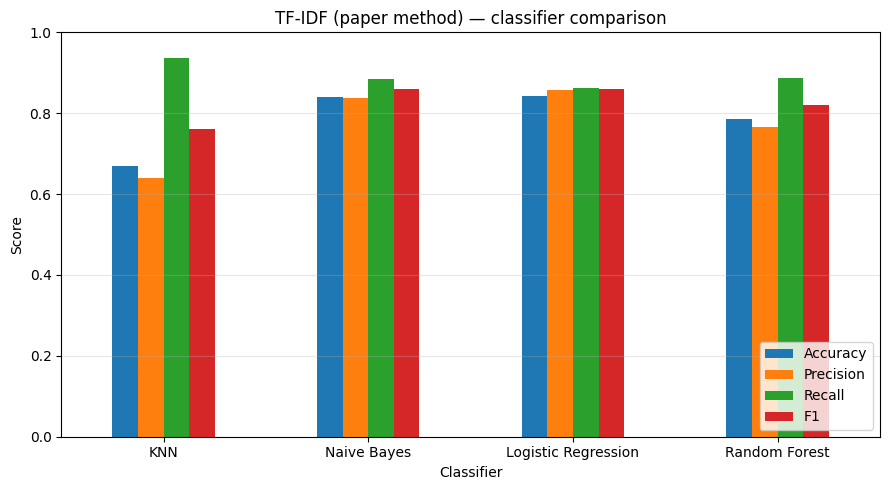

In [ ]:
## TF-IDF (paper) — SST-2 vs IMDB (reuse classifier results)
import pandas as pd
import matplotlib.pyplot as plt

results = pd.concat([
    pd.DataFrame(knn_results), pd.DataFrame(nb_results),
    pd.DataFrame(lr_results), pd.DataFrame(rf_results),
], ignore_index=True)

tfidf_paper = results[results["Representation"] == "TF-IDF (paper)"].copy()
display(tfidf_paper.round(4))

pivot = tfidf_paper.pivot(index="Classifier", columns="Dataset", values="Accuracy")
ax = pivot.plot(kind="bar", figsize=(9, 5), rot=0, ylim=(0, 1))
ax.set_title("TF-IDF (paper) — Accuracy on SST-2 vs IMDB")
ax.set_ylabel("Accuracy")
ax.legend(title="Dataset")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## TFIDF N-grams

,Accuracy,Precision,Recall,F1
Classifier,,,,
KNN,0.6314,0.6052,0.9760,0.7471
Naive Bayes,0.8542,0.8494,0.8978,0.8729
Logistic Regression,0.8564,0.8526,0.8978,0.8746
Random Forest,0.7774,0.7468,0.9093,0.8200


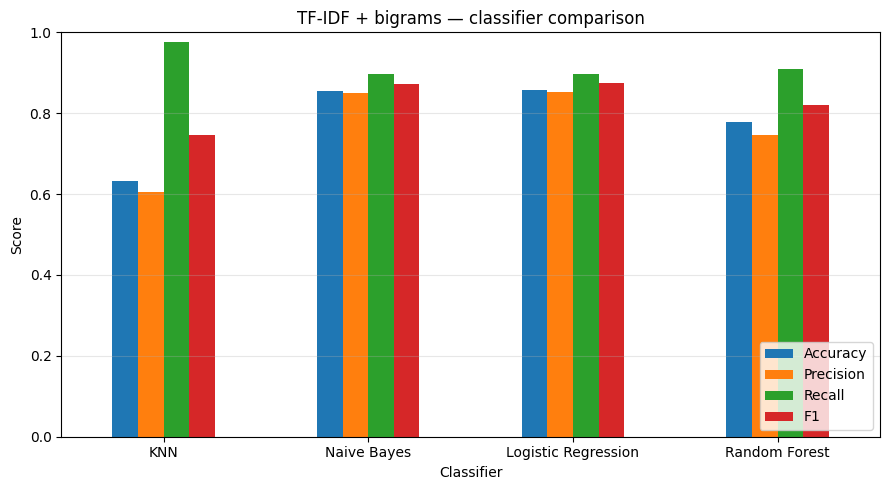

In [ ]:
## TF-IDF + bigrams — SST-2 vs IMDB (reuse classifier results)
import pandas as pd
import matplotlib.pyplot as plt

results = pd.concat([
    pd.DataFrame(knn_results), pd.DataFrame(nb_results),
    pd.DataFrame(lr_results), pd.DataFrame(rf_results),
], ignore_index=True)

tfidf_bi = results[results["Representation"] == "TF-IDF + bigrams"].copy()
display(tfidf_bi.round(4))

pivot = tfidf_bi.pivot(index="Classifier", columns="Dataset", values="Accuracy")
ax = pivot.plot(kind="bar", figsize=(9, 5), rot=0, ylim=(0, 1))
ax.set_title("TF-IDF + bigrams — Accuracy on SST-2 vs IMDB")
ax.set_ylabel("Accuracy")
ax.legend(title="Dataset")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## BW

,Accuracy,Precision,Recall,F1
Classifier,,,,
KNN,0.6900,0.6508,0.9588,0.7753
Naive Bayes,0.8358,0.8329,0.8828,0.8571
Logistic Regression,0.8368,0.8248,0.8982,0.8599
Random Forest,0.8018,0.7874,0.8831,0.8325


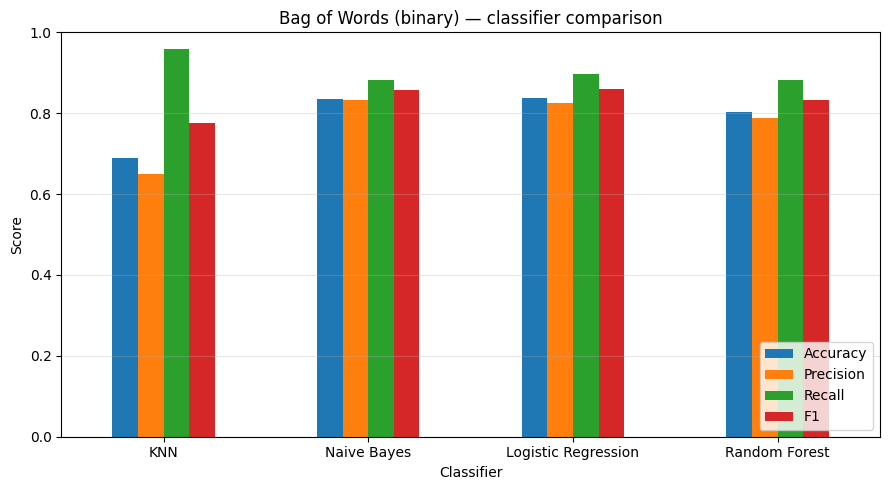

In [ ]:
## Bag of Words — SST-2 vs IMDB (reuse classifier results)
import pandas as pd
import matplotlib.pyplot as plt

results = pd.concat([
    pd.DataFrame(knn_results), pd.DataFrame(nb_results),
    pd.DataFrame(lr_results), pd.DataFrame(rf_results),
], ignore_index=True)

bow = results[results["Representation"] == "Bag of Words"].copy()
display(bow.round(4))

pivot = bow.pivot(index="Classifier", columns="Dataset", values="Accuracy")
ax = pivot.plot(kind="bar", figsize=(9, 5), rot=0, ylim=(0, 1))
ax.set_title("Bag of Words — Accuracy on SST-2 vs IMDB")
ax.set_ylabel("Accuracy")
ax.legend(title="Dataset")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## ngrams

,Accuracy,Precision,Recall,F1
Classifier,,,,
KNN,0.6868,0.6507,0.9469,0.7713
Naive Bayes,0.8322,0.8522,0.8458,0.8490
Logistic Regression,0.8498,0.8558,0.8788,0.8672
Random Forest,0.7860,0.8080,0.8085,0.8082


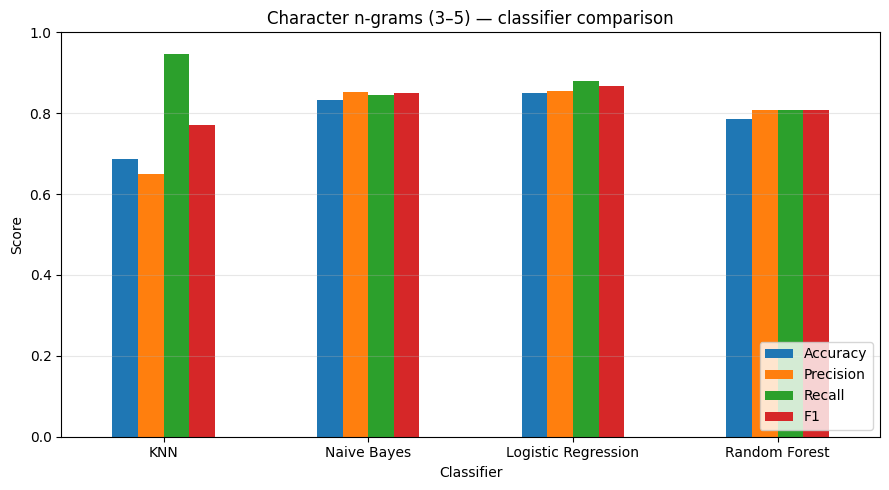

In [ ]:
## Character n-grams — SST-2 vs IMDB (reuse classifier results)
import pandas as pd
import matplotlib.pyplot as plt

results = pd.concat([
    pd.DataFrame(knn_results), pd.DataFrame(nb_results),
    pd.DataFrame(lr_results), pd.DataFrame(rf_results),
], ignore_index=True)

char_ng = results[results["Representation"] == "Character n-grams"].copy()
display(char_ng.round(4))

pivot = char_ng.pivot(index="Classifier", columns="Dataset", values="Accuracy")
ax = pivot.plot(kind="bar", figsize=(9, 5), rot=0, ylim=(0, 1))
ax.set_title("Character n-grams — Accuracy on SST-2 vs IMDB")
ax.set_ylabel("Accuracy")
ax.legend(title="Dataset")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Comparison like the paper (Table 1)

For **each** feature extraction method:
1. Train classifiers on **SST-2**
2. Evaluate on **SST-2** (in-domain) and **IMDB** (cross-domain)

Feature methods: TF-IDF (paper), TF-IDF + bigrams, Bag of Words, Character n-grams.

Metrics: Accuracy, Precision, Recall, F1-score.

In [ ]:
### Table 1 — reuse results from KNN / NB / LR / RF (no re-training)
import pandas as pd

table_all = pd.concat([
    pd.DataFrame(knn_results),
    pd.DataFrame(nb_results),
    pd.DataFrame(lr_results),
    pd.DataFrame(rf_results),
], ignore_index=True)

# Align column name with paper table
if "F1" in table_all.columns and "F1-score" not in table_all.columns:
    table_all = table_all.rename(columns={"F1": "F1-score"})

table_all = table_all.round(2)
display(table_all)

# One Table-1-like view per representation
for feat_name in feature_sets:
    print(f"\n--- {feat_name} ---")
    sub = table_all[table_all["Representation"] == feat_name].drop(columns=["Representation"])
    # paper-style: Model then Dataset
    sub = sub.rename(columns={"Classifier": "Model"})
    display(sub.set_index(["Model", "Dataset"]))


===== TF-IDF (paper) =====
  Training KNN...
  Training Random Forest...
  Training Naive Bayes...
  Training Logistic Regression...

===== TF-IDF + bigrams =====
  Training KNN...
  Training Random Forest...
  Training Naive Bayes...
  Training Logistic Regression...

===== Bag of Words =====
  Training KNN...
  Training Random Forest...
  Training Naive Bayes...
  Training Logistic Regression...

===== Character n-grams =====
  Training KNN...
  Training Random Forest...
  Training Naive Bayes...
  Training Logistic Regression...


,Representation,Model,Dataset,Accuracy,Precision,Recall,F1-score
0,TF-IDF (paper),KNN,SST-2,0.67,0.64,0.94,0.76
1,TF-IDF (paper),KNN,IMDB,0.50,0.50,1.00,0.67
2,TF-IDF (paper),Random Forest,SST-2,0.78,0.77,0.89,0.82
3,TF-IDF (paper),Random Forest,IMDB,0.55,0.53,0.95,0.68
4,TF-IDF (paper),Naive Bayes,SST-2,0.84,0.84,0.88,0.86
5,TF-IDF (paper),Naive Bayes,IMDB,0.78,0.74,0.85,0.79
6,TF-IDF (paper),Logistic Regression,SST-2,0.84,0.86,0.86,0.86
7,TF-IDF (paper),Logistic Regression,IMDB,0.79,0.78,0.80,0.79
8,TF-IDF + bigrams,KNN,SST-2,0.63,0.61,0.98,0.75
9,TF-IDF + bigrams,KNN,IMDB,0.50,0.50,1.00,0.67



--- TF-IDF (paper) ---


Accuracy  Precision  Recall  F1-score
Model               Dataset                                       
KNN                 SST-2        0.67       0.64    0.94      0.76
                    IMDB         0.50       0.50    1.00      0.67
Random Forest       SST-2        0.78       0.77    0.89      0.82
                    IMDB         0.55       0.53    0.95      0.68
Naive Bayes         SST-2        0.84       0.84    0.88      0.86
                    IMDB         0.78       0.74    0.85      0.79
Logistic Regression SST-2        0.84       0.86    0.86      0.86
                    IMDB         0.79       0.78    0.80      0.79


--- TF-IDF + bigrams ---


Accuracy  Precision  Recall  F1-score
Model               Dataset                                       
KNN                 SST-2        0.63       0.61    0.98      0.75
                    IMDB         0.50       0.50    1.00      0.67
Random Forest       SST-2        0.78       0.75    0.91      0.82
                    IMDB         0.52       0.51    0.97      0.67
Naive Bayes         SST-2        0.85       0.85    0.90      0.87
                    IMDB         0.75       0.68    0.93      0.79
Logistic Regression SST-2        0.86       0.85    0.90      0.87
                    IMDB         0.79       0.75    0.85      0.80


--- Bag of Words ---


Accuracy  Precision  Recall  F1-score
Model               Dataset                                       
KNN                 SST-2        0.69       0.65    0.96      0.78
                    IMDB         0.59       0.59    0.63      0.61
Random Forest       SST-2        0.80       0.79    0.88      0.83
                    IMDB         0.60       0.66    0.42      0.51
Naive Bayes         SST-2        0.84       0.83    0.88      0.86
                    IMDB         0.78       0.87    0.67      0.76
Logistic Regression SST-2        0.84       0.82    0.90      0.86
                    IMDB         0.78       0.87    0.67      0.76


--- Character n-grams ---


Accuracy  Precision  Recall  F1-score
Model               Dataset                                       
KNN                 SST-2        0.69       0.65    0.95      0.77
                    IMDB         0.62       0.58    0.83      0.68
Random Forest       SST-2        0.79       0.81    0.81      0.81
                    IMDB         0.56       0.56    0.53      0.54
Naive Bayes         SST-2        0.83       0.85    0.85      0.85
                    IMDB         0.71       0.92    0.46      0.61
Logistic Regression SST-2        0.85       0.86    0.88      0.87
                    IMDB         0.76       0.88    0.61      0.72

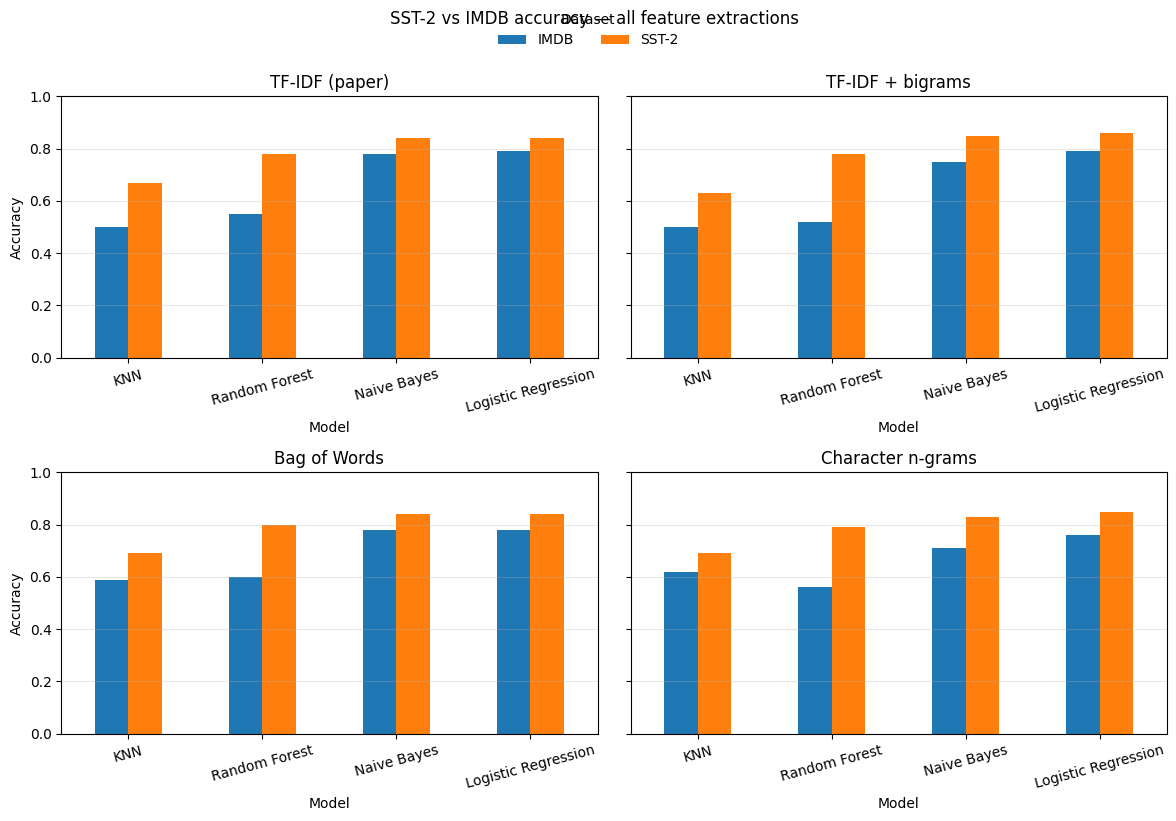

In [ ]:
# Bar plots: Accuracy SST-2 vs IMDB — one panel per feature extraction
order = ["KNN", "Random Forest", "Naive Bayes", "Logistic Regression"]
feat_names = list(feature_sets.keys())

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
axes = axes.ravel()

for ax, feat_name in zip(axes, feat_names):
    sub = table_all[table_all["Representation"] == feat_name]
    # results use "Classifier"; rename for plot if needed
    if "Classifier" in sub.columns and "Model" not in sub.columns:
        sub = sub.rename(columns={"Classifier": "Model"})
    pivot_acc = sub.pivot(index="Model", columns="Dataset", values="Accuracy").reindex(order)
    pivot_acc.plot(kind="bar", ax=ax, rot=15, ylim=(0, 1), legend=False)
    ax.set_title(feat_name)
    ax.set_ylabel("Accuracy")
    ax.grid(axis="y", alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Dataset", loc="upper center", ncol=2, frameon=False)
fig.suptitle("SST-2 vs IMDB accuracy — all feature extractions", y=1.02)
plt.tight_layout()
plt.show()

# Optional: save full table
# table_all.to_csv("table1_all_features_sst2_vs_imdb.csv", index=False)

## Confusion matrices

Train on **SST-2** with **TF-IDF (paper method)**, then plot confusion matrices for each classifier on SST-2 and IMDB.

In [ ]:
## Confusion matrices — reuse predictions (TF-IDF paper only, no re-training)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

models_cm = ["KNN", "Random Forest", "Naive Bayes", "Logistic Regression"]
feat_cm = "TF-IDF (paper)"

fig, axes = plt.subplots(4, 2, figsize=(10, 14))
for row, model_name in enumerate(models_cm):
    for col, ds in enumerate(["SST-2", "IMDB"]):
        y_true, y_pred = all_predictions[(model_name, feat_cm, ds)]
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        ax = axes[row, col]
        ConfusionMatrixDisplay(cm, display_labels=["Neg", "Pos"]).plot(ax=ax, colorbar=False)
        ax.set_title(f"{model_name} — {ds}")
plt.suptitle(f"Confusion matrices — {feat_cm}", y=1.01)
plt.tight_layout()
plt.show()

for model_name in models_cm:
    for ds in ["SST-2", "IMDB"]:
        y_true, y_pred = all_predictions[(model_name, feat_cm, ds)]
        print("\n", "=" * 50)
        print(f"{model_name} — {ds} ({feat_cm})")
        print(classification_report(
            y_true, y_pred, target_names=["Negative", "Positive"], digits=4
        ))